In [78]:
#Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

In [79]:
# Load the CSV file
file_path = "2019.csv"

if not Path(file_path).exists():
    raise FileNotFoundError(
        f"Could not find {file_path}. Place the CSV beside this notebook "
        "or update file_path to the correct location."
    )

df = pd.read_csv(file_path)
print("=" * 60)
print("WORLD HAPPINESS REPORT 2019")
print("=" * 60)
print("Dataset loaded successfully.")

WORLD HAPPINESS REPORT 2019
Dataset loaded successfully.


In [80]:
# Inspect the dataset

print("Number of rows and columns:", df.shape)

Number of rows and columns: (156, 9)


In [81]:
print("\nFirst five rows:")
display(df.head())


First five rows:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [82]:
print("Last five rows:")
display(df.tail())

Last five rows:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
151,152,Rwanda,3.334,0.359,0.711,0.614,0.555,0.217,0.411
152,153,Tanzania,3.231,0.476,0.885,0.499,0.417,0.276,0.147
153,154,Afghanistan,3.203,0.350,0.517,0.361,0.000,0.158,0.025
154,155,Central African Republic,3.083,0.026,0.000,0.105,0.225,0.235,0.035
155,156,South Sudan,2.853,0.306,0.575,0.295,0.010,0.202,0.091


In [83]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']


In [84]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [85]:
print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))


Missing values in each column:


,Missing Values
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [86]:
print("\nNumber of duplicated rows:", df.duplicated().sum())


Number of duplicated rows: 0


In [87]:
#Data cleaning and preparation

# Remove fully duplicated records only if any are present.
df = df.drop_duplicates().copy()

# Remove extra spaces from column names and country names.
df.columns = df.columns.str.strip()
df["Country or region"] = df["Country or region"].astype("string").str.strip()

# Convert expected measurement columns to numeric values.
numeric_columns = [
    "Overall rank", "Score", "GDP per capita", "Social support",
    "Healthy life expectancy", "Freedom to make life choices",
    "Generosity", "Perceptions of corruption"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("Missing Values"))

Shape after cleaning: (156, 9)

Missing values after cleaning:


,Missing Values
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [88]:
#Descriptive statistics
print("Summary statistics for numeric columns:")
display(df[numeric_columns].describe().T)

Summary statistics for numeric columns:


,count,mean,std,min,25%,50%,75%,max
Overall rank,156.000,78.500,45.177,1.000,39.750,78.500,117.250,156.000
Score,156.000,5.407,1.113,2.853,4.545,5.380,6.184,7.769
GDP per capita,156.000,0.905,0.398,0.000,0.603,0.960,1.233,1.684
Social support,156.000,1.209,0.299,0.000,1.056,1.272,1.452,1.624
Healthy life expectancy,156.000,0.725,0.242,0.000,0.548,0.789,0.882,1.141
Freedom to make life choices,156.000,0.393,0.143,0.000,0.308,0.417,0.507,0.631
Generosity,156.000,0.185,0.095,0.000,0.109,0.177,0.248,0.566
Perceptions of corruption,156.000,0.111,0.095,0.000,0.047,0.085,0.141,0.453


In [89]:
print("Dataset data types:")
display(df.dtypes.to_frame("Data Type"))

Dataset data types:


,Data Type
Overall rank,int64
Country or region,string[python]
Score,float64
GDP per capita,float64
Social support,float64
Healthy life expectancy,float64
Freedom to make life choices,float64
Generosity,float64
Perceptions of corruption,float64


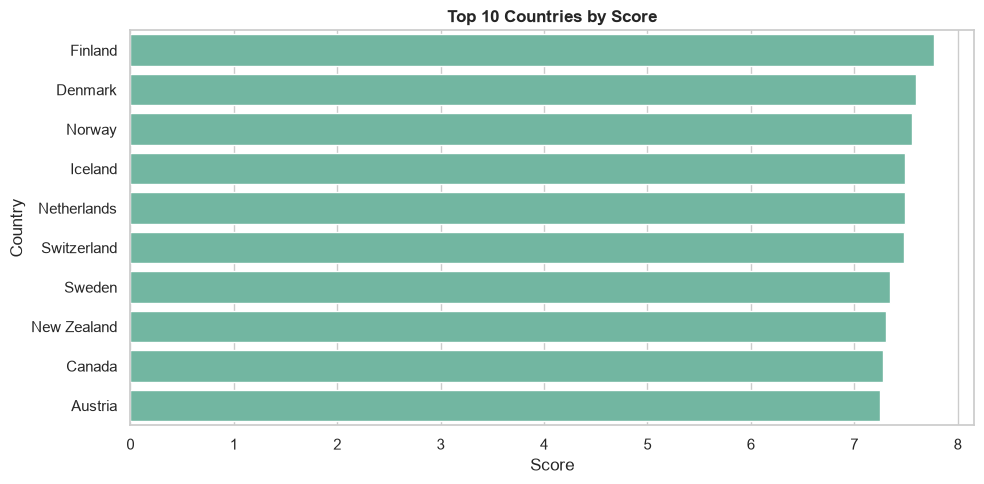

In [90]:
plot_data = df[["Country or region", "Score"]].dropna()
plot_data = plot_data.sort_values("Score", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="Score", y="Country or region")

plt.title("Top 10 Countries by Score")
plt.xlabel("Score")
plt.ylabel("Country")
plt.tight_layout()
plt.show()



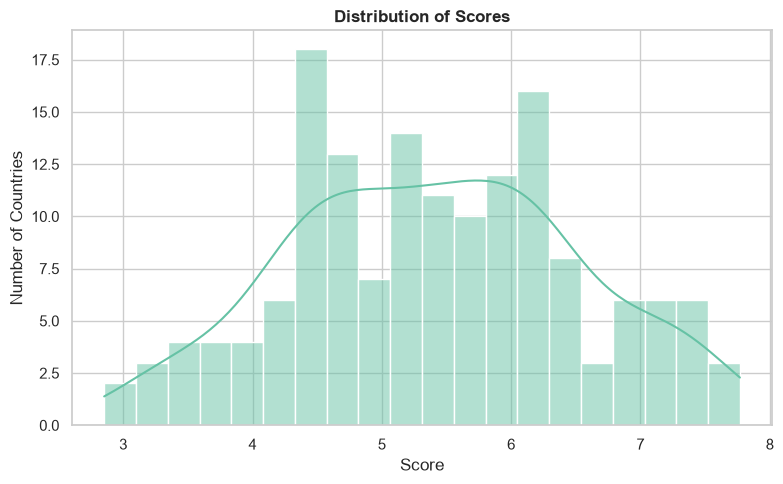

In [91]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Score"].dropna(), bins=20, kde=True)

plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Number of Countries")
plt.tight_layout()
plt.show()

In [92]:
result = df[["Score", "GDP per capita"]].corr().iloc[0, 1]

print(f"Correlation between Score and GDP per capita: {result:.3f}")


Correlation between Score and GDP per capita: 0.794


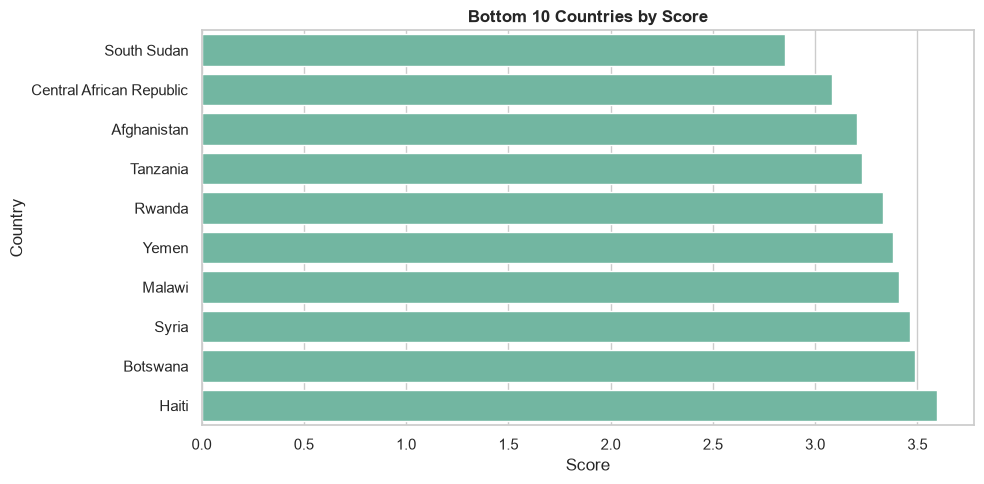

In [93]:
plot_data = df[["Country or region", "Score"]].dropna()
plot_data = plot_data.sort_values("Score", ascending=True).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="Score", y="Country or region")

plt.title("Bottom 10 Countries by Score")
plt.xlabel("Score")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

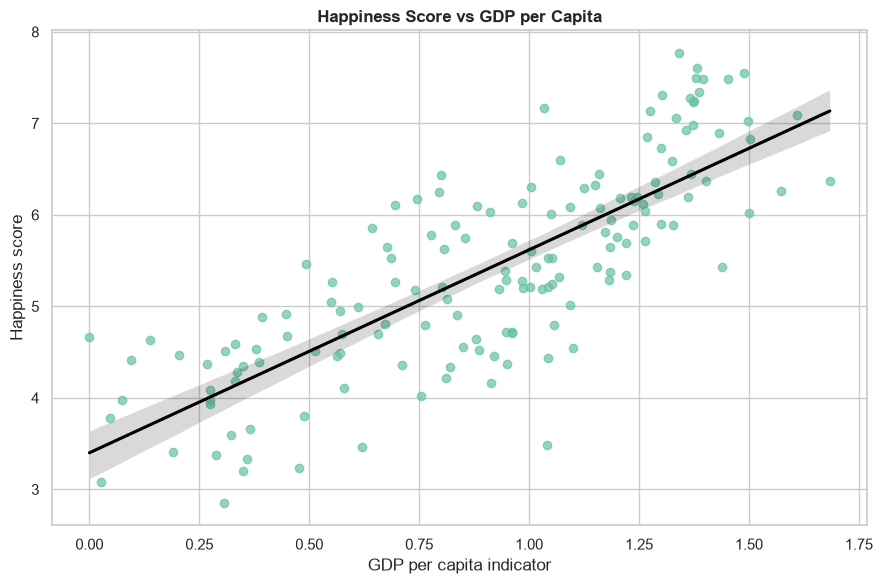

Correlation between GDP per capita and Score: 0.794


In [94]:
#Happiness score vs GDP per capita
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x="GDP per capita", y="Score",
            scatter_kws={"alpha": 0.7}, line_kws={"color": "black"})
plt.title("Happiness Score vs GDP per Capita")
plt.xlabel("GDP per capita indicator")
plt.ylabel("Happiness score")
plt.tight_layout()
plt.show()
print_correlation(df, "GDP per capita", "Score")

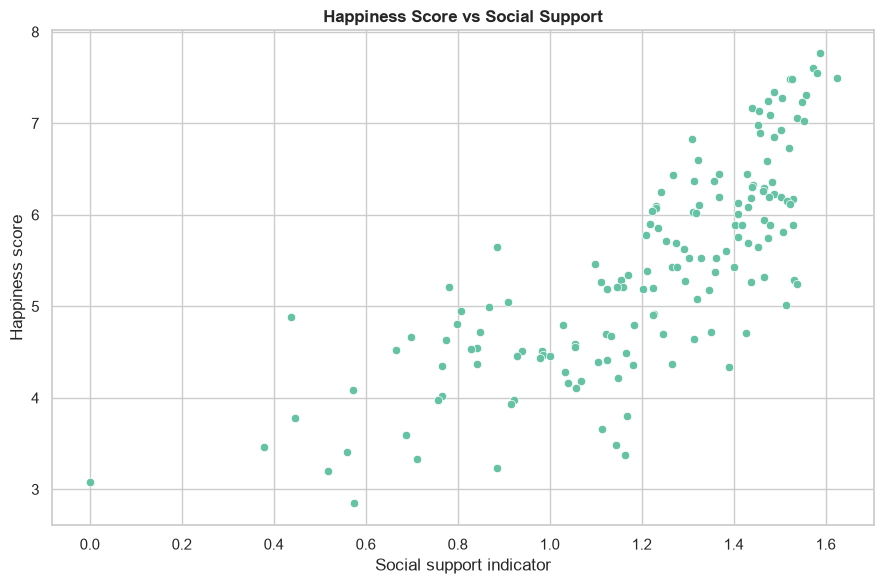

Correlation between Social support and Score: 0.777


In [95]:
#Happiness score vs social support
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Social support", y="Score")
plt.title("Happiness Score vs Social Support")
plt.xlabel("Social support indicator")
plt.ylabel("Happiness score")
plt.tight_layout()
plt.show()
print_correlation(df, "Social support", "Score")

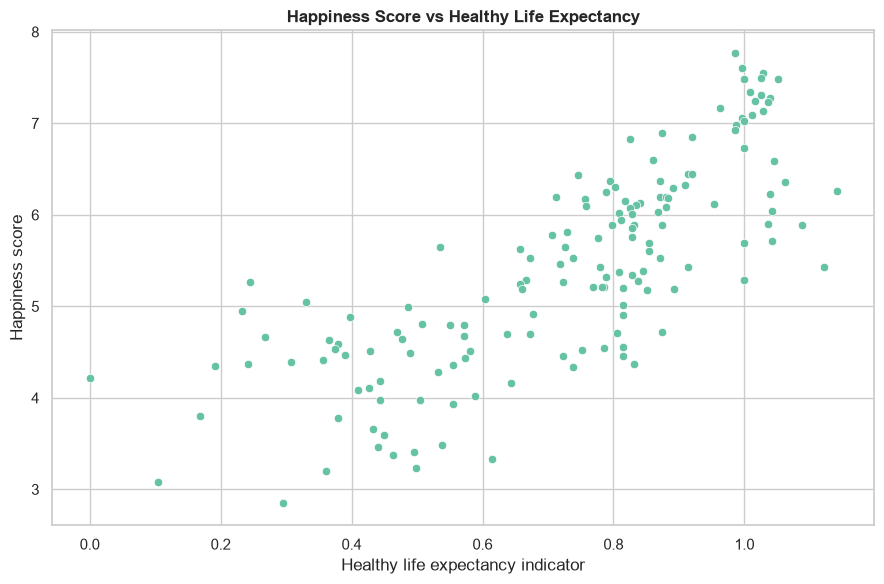

Correlation between Healthy life expectancy and Score: 0.780


In [96]:
#Happiness score vs healthy life expectancy
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Healthy life expectancy", y="Score")
plt.title("Happiness Score vs Healthy Life Expectancy")
plt.xlabel("Healthy life expectancy indicator")
plt.ylabel("Happiness score")
plt.tight_layout()
plt.show()
print_correlation(df, "Healthy life expectancy", "Score")

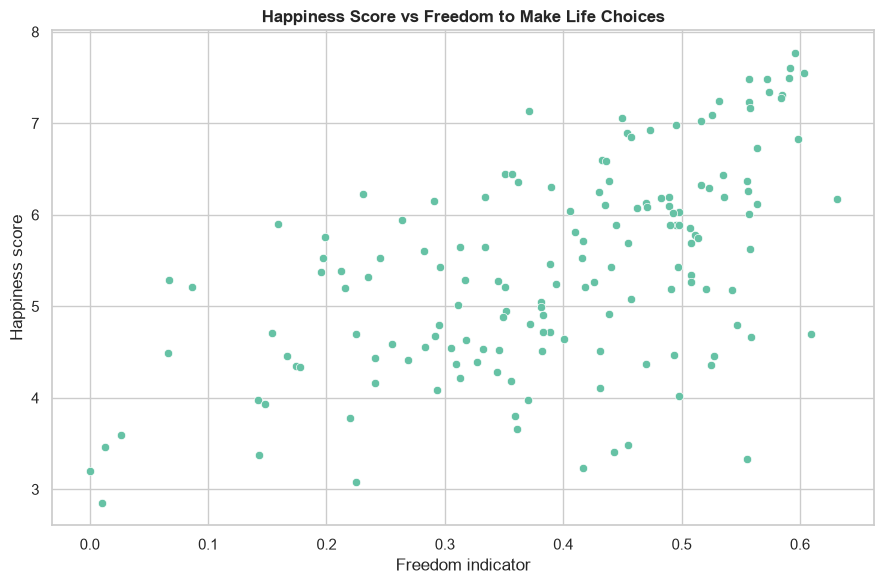

Correlation between Freedom to make life choices and Score: 0.567


In [97]:
#Happiness score vs freedom to make life choices
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Freedom to make life choices", y="Score")
plt.title("Happiness Score vs Freedom to Make Life Choices")
plt.xlabel("Freedom indicator")
plt.ylabel("Happiness score")
plt.tight_layout()
plt.show()
print_correlation(df, "Freedom to make life choices", "Score")

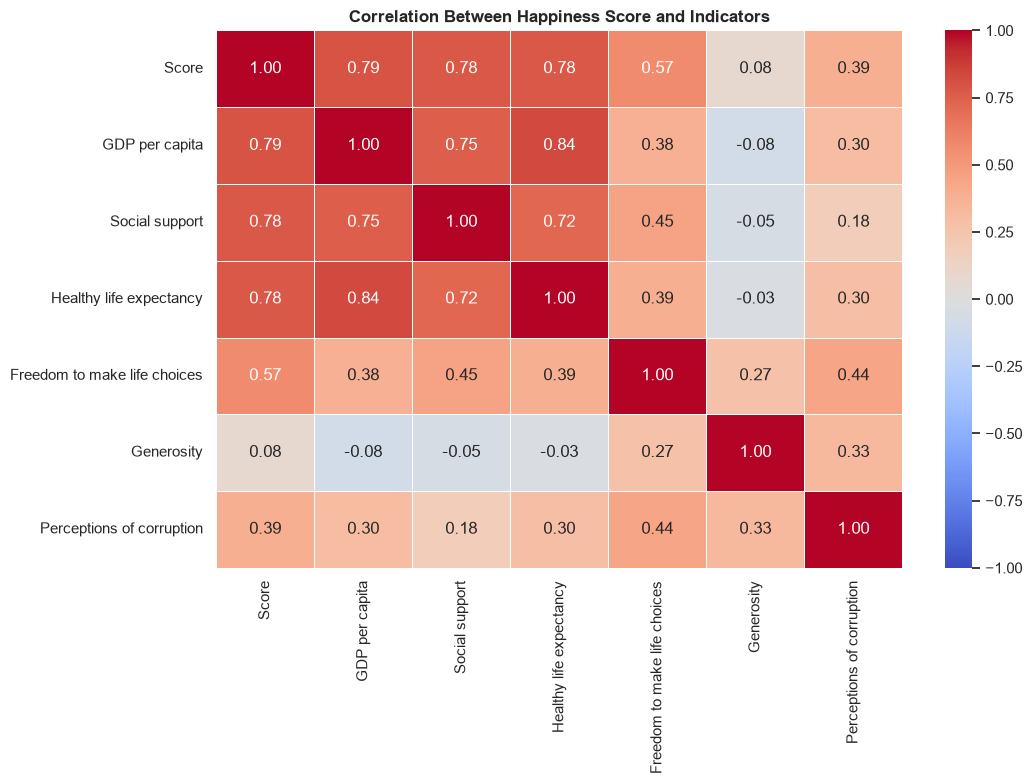

In [98]:
#Correlation heatmap
correlation_columns = ["Score"] + indicator_columns
correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Between Happiness Score and Indicators")
plt.tight_layout()
plt.show()

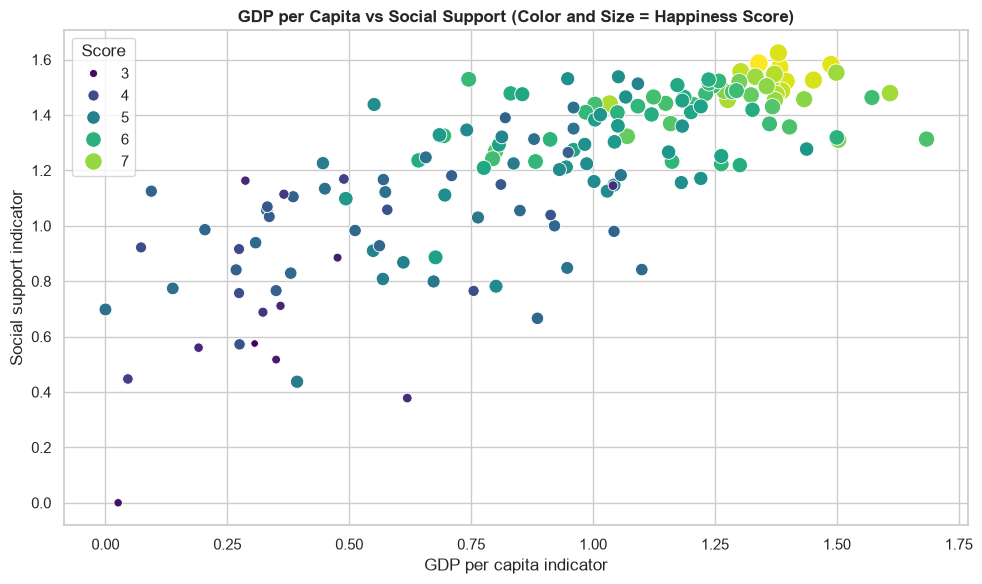

In [99]:
#GDP and social support together
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, x="GDP per capita", y="Social support",
    hue="Score", size="Score", sizes=(30, 180), palette="viridis"
)
plt.title("GDP per Capita vs Social Support (Color and Size = Happiness Score)")
plt.xlabel("GDP per capita indicator")
plt.ylabel("Social support indicator")
plt.tight_layout()
plt.show()

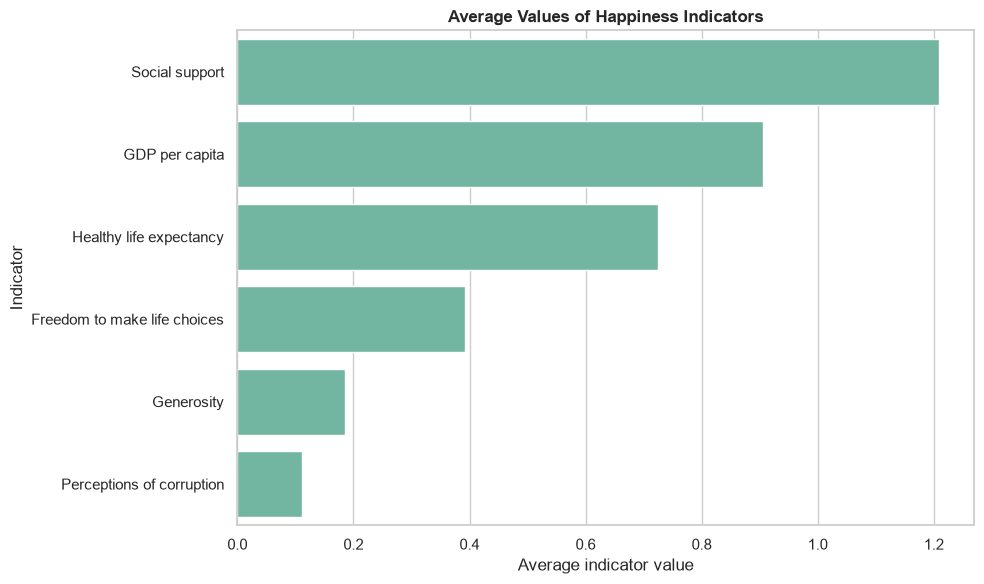

In [100]:
#Compare indicator averages
average_indicators = df[indicator_columns].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=average_indicators.values, y=average_indicators.index)
plt.title("Average Values of Happiness Indicators")
plt.xlabel("Average indicator value")
plt.ylabel("Indicator")
plt.tight_layout()
plt.show()

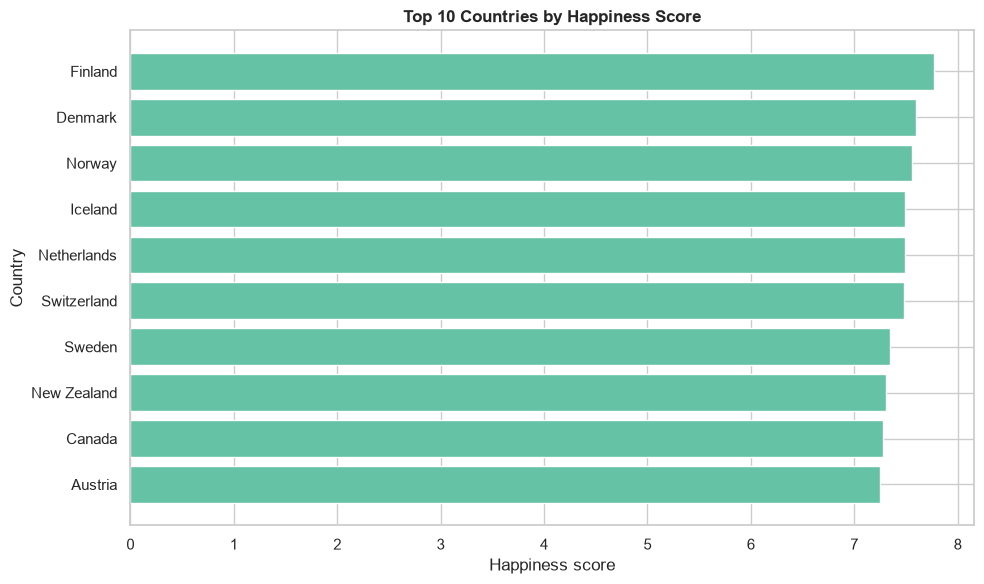

In [101]:
#Top 10 countries: score and rank
top_countries = df.nlargest(10, "Score").sort_values("Score", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(top_countries["Country or region"], top_countries["Score"])
plt.title("Top 10 Countries by Happiness Score")
plt.xlabel("Happiness score")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [102]:
# Select the five highest-scoring countries and compare their indicators.
top_five = df.nlargest(5, "Score").set_index("Country or region")
display(top_five[["Score"] + indicator_columns[0:5]])

,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity
Country or region,,,,,,
Finland,7.769,1.340,1.587,0.986,0.596,0.153
Denmark,7.600,1.383,1.573,0.996,0.592,0.252
Norway,7.554,1.488,1.582,1.028,0.603,0.271
Iceland,7.494,1.380,1.624,1.026,0.591,0.354
Netherlands,7.488,1.396,1.522,0.999,0.557,0.322


In [103]:
#Key findings generated from the dataset
highest = df.loc[df["Score"].idxmax()]
lowest = df.loc[df["Score"].idxmin()]
print(f"Countries included: {df['Country or region'].nunique()}")
print(f"Average happiness score: {df['Score'].mean():.3f}")
print(f"Median happiness score: {df['Score'].median():.3f}")
print(f"Highest score: {highest['Country or region']} ({highest['Score']:.3f})")
print(f"Lowest score: {lowest['Country or region']} ({lowest['Score']:.3f})")
print("\nCorrelation with happiness score:")
display(df[["Score"] + indicator_columns].corr()["Score"].drop("Score").sort_values(ascending=False).to_frame("Correlation with Score"))

Countries included: 156
Average happiness score: 5.407
Median happiness score: 5.380
Highest score: Finland (7.769)
Lowest score: South Sudan (2.853)

Correlation with happiness score:


,Correlation with Score
GDP per capita,0.794
Healthy life expectancy,0.780
Social support,0.777
Freedom to make life choices,0.567
Perceptions of corruption,0.386
Generosity,0.076


In [104]:
#Conclusion
print("=" * 60)
print("PROJECT EXECUTION COMPLETED SUCCESSFULLY!")
print("=" * 60)
print("Dataset: World Happiness Report 2019")
print("Rows:", len(df))
print("Columns:", len(df.columns))

PROJECT EXECUTION COMPLETED SUCCESSFULLY!
Dataset: World Happiness Report 2019
Rows: 156
Columns: 9
